# Modeling on 30-second windows: naive baseline vs. tuned ridge vs. tuned gradient boosting

Same pipeline as `modeling.ipynb`, but trained on `data/bp_training_dataset_30s.csv`
instead of `data/ppg_features.csv`. This file has the **same 14 PPG features and the
same columns**, but each row summarizes a **30-second window** instead of a 5-second
one, so there are fewer, longer windows (fewer, more heartbeats averaged into each
row's features).

**Purpose:** directly compare whether longer windows produce lower MAE/RMSE than the
original 5-second windows, with everything else (split logic, CV grids, random seeds,
model code) held identical.

Pipeline, using the shared code in `../src/`:

1. Load `data/bp_training_dataset_30s.csv`.
2. Split into train/test **by whole recording** (`src/data_split.py`).
3. Compute the **naive baseline** (`src/baseline.py`).
4. **Tune hyperparameters** using grouped K-fold cross-validation *within the train
   set only* (`src/cross_validation.py`) — same grids as `modeling.ipynb`.
5. Refit the winning hyperparameters on the full train set, evaluate once on the
   held-out test recordings.
6. Explain predictions with ridge coefficients and GBM permutation importance.

Run this notebook from `notebooks/`.

## Setup

In [1]:
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path('..').resolve()))

from src.data_split import grouped_train_test_split, split_summary
from src.baseline import compute_naive_baseline, evaluate_naive_baseline
from src.models import FEATURE_COLUMNS, fit_gbm, fit_ridge, evaluate_model
from src.cross_validation import ridge_alpha_search, gbm_param_search, RIDGE_ALPHA_GRID, GBM_PARAM_GRID
from src.importance import importance_report
from src.baseline import evaluate_predictions

results_dir = Path('../results')
graphs_dir = results_dir / 'graphs'
graphs_dir.mkdir(parents=True, exist_ok=True)

TARGET_COLS = ('sbp', 'dbp')
RANDOM_STATE = 42
N_SPLITS = 5

## 1. Load the feature table

One row per usable 30-second window: same 14 PPG features, SBP/DBP labels, and source
IDs (`file`, `record_index`, `start_sample`) as `ppg_features.csv`.

In [2]:
df = pd.read_csv('../data/bp_training_dataset_30s.csv')
assert set(FEATURE_COLUMNS).issubset(df.columns)
assert set(TARGET_COLS).issubset(df.columns)
print(f'Loaded {len(df):,} rows, {df["file"].nunique()} source file(s), '
      f'{df[["file", "record_index"]].drop_duplicates().shape[0]:,} recordings.')
df.head()

Loaded 83,419 rows, 4 source file(s), 9,623 recordings.


,file,record_index,start_sample,inband_power_ratio,sbp,dbp,heart_rate_bpm,beat_interval_std_ms,pulse_height,rise_time_s,...,rise_fall_ratio,pulse_width_s,max_upslope,ppg_std,ppg_min,ppg_max,ppg_range,ppg_skewness,ppg_kurtosis,n_beats
0,Part_1.mat,0,0,0.987359,124.601310,68.625967,123.490670,6.173780,1.866039,0.140475,...,0.407221,0.173831,22.877494,0.616733,-1.024048,1.370144,2.394192,0.531458,-1.118607,59
1,Part_1.mat,0,3750,0.950578,127.873865,69.749381,121.867254,18.649860,1.839644,0.145379,...,0.430643,0.179034,22.186650,0.628346,-1.491121,1.697561,3.188682,0.469958,-0.943795,58
2,Part_1.mat,0,7500,0.980027,127.214470,68.845765,120.375408,37.269641,1.844009,0.145103,...,0.421256,0.174897,22.351117,0.628136,-1.424346,1.968505,3.392850,0.524399,-0.836404,58
3,Part_1.mat,0,11250,0.987171,126.384120,69.114408,123.983740,7.474259,1.879048,0.138933,...,0.402368,0.170000,23.234042,0.628382,-1.163292,1.476256,2.639548,0.544356,-1.067562,60
4,Part_1.mat,0,15000,0.986565,128.044819,69.798225,124.659401,6.004209,1.881801,0.138800,...,0.405430,0.170267,23.210829,0.630809,-1.135296,1.290233,2.425529,0.524669,-1.114252,60


## 2. Split by recording

Same 80/20 grouped split as `modeling.ipynb`, same `random_state`.

In [3]:
train_df, test_df = grouped_train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
split_summary(train_df, test_df)

,split,rows,recordings
0,train,66381,7697
1,test,17038,1926


## 3. Naive baseline

In [4]:
baseline_values = compute_naive_baseline(train_df, TARGET_COLS)
baseline_results = evaluate_naive_baseline(baseline_values, test_df, TARGET_COLS)
print('Naive baseline (train-set mean):', baseline_values)
baseline_results.round(3)

Naive baseline (train-set mean): {'sbp': 129.17787746322685, 'dbp': 67.60697564640209}


,target,predicted_value,mae,rmse
0,sbp,129.178,17.974,21.985
1,dbp,67.607,8.581,11.226


## 4. Hyperparameter tuning (grouped K-fold CV, train set only)

Same grids as `modeling.ipynb`:

- **Ridge**: `alpha` in `[0.001, 0.01, 0.1, 1, 10, 100, 1000]`.
- **Gradient boosting**: `learning_rate` x `max_leaf_nodes` x `min_samples_leaf`
  (45 combinations).

In [5]:
ridge_cv_results = {}
ridge_best_alpha = {}

for target in TARGET_COLS:
    results, search = ridge_alpha_search(train_df, target, n_splits=N_SPLITS, random_state=RANDOM_STATE)
    ridge_cv_results[target] = results
    ridge_best_alpha[target] = search.best_params_['ridge__alpha']
    print(f'--- Ridge CV for {target.upper()} ---')
    display(results)
    print(f'Best alpha: {ridge_best_alpha[target]}\n')

--- Ridge CV for SBP ---


,params,rank,mean_mae,std_mae
0,{'ridge__alpha': 0.001},1,17.087428,0.273683
1,{'ridge__alpha': 0.01},2,17.087428,0.273683
2,{'ridge__alpha': 0.1},3,17.087433,0.273682
3,{'ridge__alpha': 1},4,17.087483,0.273677
4,{'ridge__alpha': 10},5,17.088006,0.273630
5,{'ridge__alpha': 100},6,17.095704,0.273122
6,{'ridge__alpha': 1000},7,17.174149,0.274086


Best alpha: 0.001



--- Ridge CV for DBP ---


,params,rank,mean_mae,std_mae
0,{'ridge__alpha': 0.001},1,8.308951,0.091892
1,{'ridge__alpha': 0.01},2,8.308952,0.091892
2,{'ridge__alpha': 0.1},3,8.308958,0.091892
3,{'ridge__alpha': 1},4,8.309022,0.091893
4,{'ridge__alpha': 10},5,8.309660,0.091897
5,{'ridge__alpha': 100},6,8.315902,0.091914
6,{'ridge__alpha': 1000},7,8.356322,0.090844


Best alpha: 0.001



In [6]:
gbm_cv_results = {}
gbm_best_params = {}

for target in TARGET_COLS:
    results, search = gbm_param_search(train_df, target, n_splits=N_SPLITS, random_state=RANDOM_STATE)
    gbm_cv_results[target] = results
    gbm_best_params[target] = search.best_params_
    print(f'--- Gradient boosting CV for {target.upper()} (top 5 of {len(results)} combos) ---')
    display(results.head())
    print(f'Best params: {gbm_best_params[target]}\n')

--- Gradient boosting CV for SBP (top 5 of 45 combos) ---


,params,rank,mean_mae,std_mae
0,"{'learning_rate': 0.05, 'max_leaf_nodes': 1000...",1,13.711064,0.256329
1,"{'learning_rate': 0.05, 'max_leaf_nodes': 316,...",2,13.827558,0.260897
2,"{'learning_rate': 0.1, 'max_leaf_nodes': 1000,...",3,13.853802,0.257120
3,"{'learning_rate': 0.1, 'max_leaf_nodes': 316, ...",4,13.911378,0.257600
4,"{'learning_rate': 0.05, 'max_leaf_nodes': 316,...",5,13.970448,0.287911


Best params: {'learning_rate': 0.05, 'max_leaf_nodes': 1000, 'min_samples_leaf': 20}



--- Gradient boosting CV for DBP (top 5 of 45 combos) ---


,params,rank,mean_mae,std_mae
0,"{'learning_rate': 0.05, 'max_leaf_nodes': 316,...",1,7.192177,0.085089
1,"{'learning_rate': 0.05, 'max_leaf_nodes': 1000...",2,7.192582,0.066676
2,"{'learning_rate': 0.1, 'max_leaf_nodes': 316, ...",3,7.239249,0.075114
3,"{'learning_rate': 0.1, 'max_leaf_nodes': 1000,...",4,7.252331,0.072370
4,"{'learning_rate': 0.1, 'max_leaf_nodes': 100, ...",5,7.261117,0.074747


Best params: {'learning_rate': 0.05, 'max_leaf_nodes': 316, 'min_samples_leaf': 20}



## 5. Refit with the winning hyperparameters, evaluate once on the test set

In [7]:
rows = []
fitted_models = {}

for target in TARGET_COLS:
    import numpy as np
    constant_pred = np.full(len(test_df), baseline_values[target])
    rows.append({'target': target, 'model': 'naive_baseline',
                 **evaluate_predictions(test_df[target], constant_pred)})

    ridge_model = fit_ridge(train_df, target, FEATURE_COLUMNS, alpha=ridge_best_alpha[target])
    fitted_models[(target, 'ridge')] = ridge_model
    rows.append({'target': target, 'model': 'ridge (tuned)',
                 **evaluate_model(ridge_model, test_df, target, FEATURE_COLUMNS)})

    gbm_model = fit_gbm(train_df, target, FEATURE_COLUMNS, random_state=RANDOM_STATE, **gbm_best_params[target])
    fitted_models[(target, 'gbm')] = gbm_model
    rows.append({'target': target, 'model': 'gbm (tuned)',
                 **evaluate_model(gbm_model, test_df, target, FEATURE_COLUMNS)})

results = pd.DataFrame(rows)[['target', 'model', 'mae', 'rmse']]
results.round(3)

,target,model,mae,rmse
0,sbp,naive_baseline,17.974,21.985
1,sbp,ridge (tuned),16.977,21.107
2,sbp,gbm (tuned),13.828,18.554
3,dbp,naive_baseline,8.581,11.226
4,dbp,ridge (tuned),8.196,10.817
5,dbp,gbm (tuned),7.096,9.989


## 6. Compare the three models

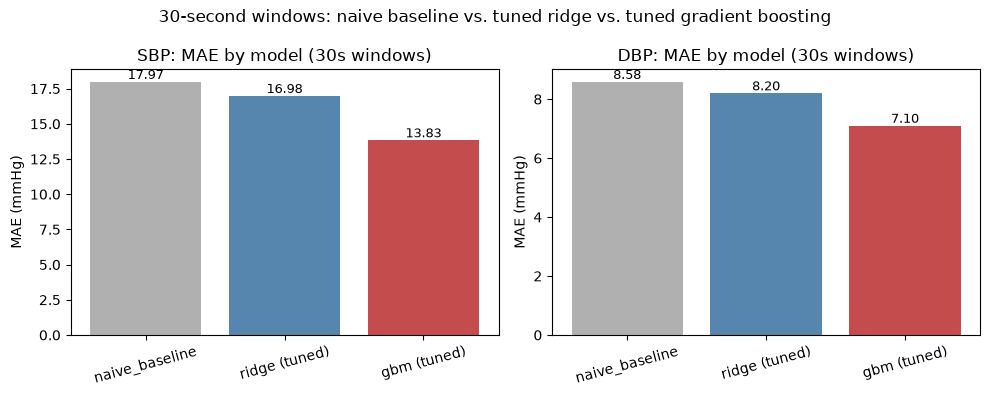

In [8]:
import matplotlib.pyplot as plt

model_order = ['naive_baseline', 'ridge (tuned)', 'gbm (tuned)']
colors = {'naive_baseline': '#b0b0b0', 'ridge (tuned)': '#5686ad', 'gbm (tuned)': '#c44c4c'}

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
for ax, target in zip(axes, TARGET_COLS):
    subset = results[results['target'] == target].set_index('model').loc[model_order]
    ax.bar(model_order, subset['mae'], color=[colors[m] for m in model_order])
    ax.set_title(f'{target.upper()}: MAE by model (30s windows)')
    ax.set_ylabel('MAE (mmHg)')
    ax.tick_params(axis='x', rotation=15)
    for i, value in enumerate(subset['mae']):
        ax.text(i, value, f'{value:.2f}', ha='center', va='bottom', fontsize=9)
fig.suptitle('30-second windows: naive baseline vs. tuned ridge vs. tuned gradient boosting')
fig.tight_layout()
fig.savefig(graphs_dir / 'model_comparison_30s.png', dpi=150)
plt.show()
plt.close(fig)

## 7. Feature importance

In [9]:
importance = importance_report(fitted_models, test_df, target_cols=TARGET_COLS)
for target in TARGET_COLS:
    print(f'--- {target.upper()} ---')
    display(importance[importance['target'] == target].drop(columns='target').round(3))

--- SBP ---


,feature,coefficient,abs_coefficient,importance_mean,importance_std
0,pulse_height,-26.960,26.960,1.913,0.037
1,max_upslope,12.897,12.897,3.059,0.033
2,ppg_std,11.956,11.956,2.427,0.034
3,ppg_kurtosis,-6.027,6.027,1.084,0.031
4,heart_rate_bpm,-5.363,5.363,0.871,0.032
5,ppg_min,-2.686,2.686,0.225,0.014
6,ppg_range,1.911,1.911,0.180,0.014
7,pulse_width_s,-1.665,1.665,2.066,0.025
8,rise_fall_ratio,-1.562,1.562,1.040,0.034
9,rise_time_s,1.302,1.302,1.236,0.022


--- DBP ---


,feature,coefficient,abs_coefficient,importance_mean,importance_std
14,pulse_height,-9.695,9.695,0.708,0.013
15,max_upslope,6.790,6.790,1.532,0.019
16,ppg_std,2.797,2.797,0.374,0.015
17,pulse_width_s,1.186,1.186,0.653,0.013
18,beat_interval_std_ms,1.055,1.055,0.382,0.017
19,ppg_kurtosis,-0.960,0.960,0.441,0.015
20,ppg_min,-0.857,0.857,0.154,0.011
21,ppg_skewness,-0.624,0.624,1.076,0.022
22,fall_time_s,-0.601,0.601,0.307,0.009
23,ppg_range,0.547,0.547,0.087,0.006


## 8. Visualize feature importance

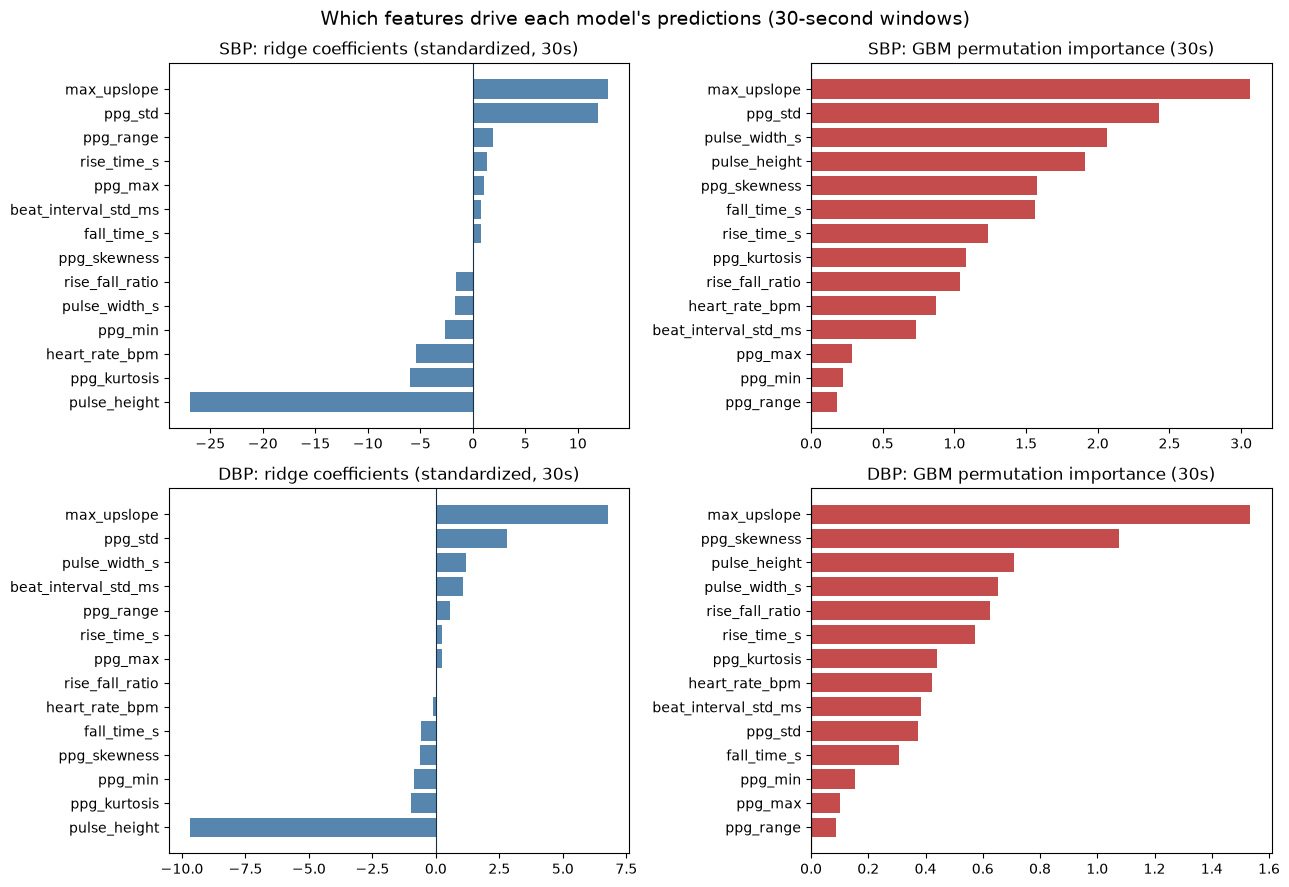

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, target in enumerate(TARGET_COLS):
    subset = importance[importance['target'] == target].set_index('feature')

    ax = axes[row, 0]
    ordered = subset.sort_values('coefficient')
    ax.barh(ordered.index, ordered['coefficient'], color='#5686ad')
    ax.set_title(f'{target.upper()}: ridge coefficients (standardized, 30s)')
    ax.axvline(0, color='#183047', linewidth=0.8)

    ax = axes[row, 1]
    ordered = subset.sort_values('importance_mean')
    ax.barh(ordered.index, ordered['importance_mean'], color='#c44c4c')
    ax.set_title(f'{target.upper()}: GBM permutation importance (30s)')
    ax.axvline(0, color='#183047', linewidth=0.8)

fig.suptitle('Which features drive each model\'s predictions (30-second windows)', fontsize=14)
fig.tight_layout()
fig.savefig(graphs_dir / 'feature_importance_30s.png', dpi=150)
plt.show()
plt.close(fig)

## Notes

- Same split logic, CV grids, and random seeds as `modeling.ipynb` — the only thing
  that changed is the input file (30-second windows instead of 5-second windows), so
  any difference in MAE/RMSE between the two notebooks reflects window length, not a
  methodology change.
- Fewer, longer windows means fewer total training rows but each row's features are
  averaged over more heartbeats, which could make the 14 features less noisy per row.